# Part 1 — Diffusion models in a nutshell
Paper §2.1, App. A.1. Read [README.md](README.md) first for the equations.

Goals: (1) understand the VP SDE, (2) train a diffusion model with denoising score matching,
(3) sample with the reverse SDE, (4) see why small diffusion times are hard.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent            # notebooks live one level below the project root
sys.path.insert(0, str(ROOT))
import numpy as np, torch, matplotlib.pyplot as plt
torch.set_default_dtype(torch.float64)      # float64: the FP estimator uses finite differences with sigma=1e-4
torch.set_num_threads(8)
from scoremd import sde, models, losses, sampling, simulate, metrics, potentials, plotting, experiments as ex
%matplotlib inline

## 1. The VP noise schedule
`x_t = m(t) x_0 + s(t) ε`. With unit-variance data, `m² + s² = 1` keeps the variance at 1 for all `t`.

s(1e-5) = 0.0010004971259111187  s(1) = 0.9999784068923386


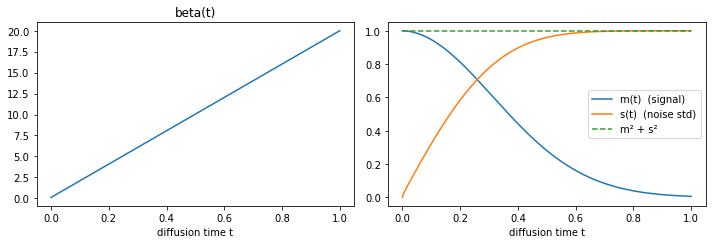

In [2]:
t = torch.linspace(0, 1, 500)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(t, sde.beta(t)); ax[0].set_title('beta(t)'); ax[0].set_xlabel('diffusion time t')
ax[1].plot(t, sde.marginal_mean_coef(t), label='m(t)  (signal)')
ax[1].plot(t, sde.marginal_std(t), label='s(t)  (noise std)')
ax[1].plot(t, sde.marginal_mean_coef(t)**2 + sde.marginal_std(t)**2, '--', label='m² + s²')
ax[1].legend(); ax[1].set_xlabel('diffusion time t'); plt.tight_layout()
print('s(1e-5) =', float(sde.marginal_std(torch.tensor(1e-5))), ' s(1) =', float(sde.marginal_std(torch.tensor(1.))))

## 2. The data: Figure 1's Gaussian mixture
`1/5 N([-5,-5], I) + 4/5 N([5,5], I)`, normalised to unit variance (App. A.1: required for this schedule).

torch.Size([100000, 2]) mean [ 0. -0.] std [0.999 1.001] | scale used: 4.122742193545731


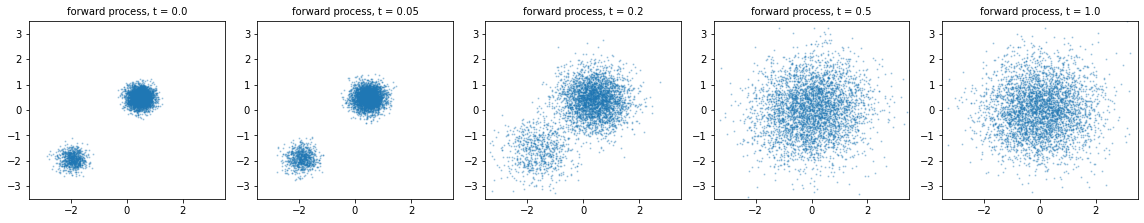

In [3]:
x, info = ex.load_system('gmm')
print(x.shape, 'mean', x.mean(0).numpy().round(3), 'std', x.std(0).numpy().round(3), '| scale used:', float(info['scale']))
fig, axs = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, tv in zip(axs, [0.0, 0.05, 0.2, 0.5, 1.0]):
    xt, _, _ = sde.perturb(x[:4000], torch.full((4000,), tv))
    plotting.scatter(ax, xt, title=f'forward process, t = {tv}'); ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5)
plt.tight_layout()

## 3. Train with denoising score matching
`L = E || s(t) s_θ(x_t, t) + ε ||²`. We use the energy-based network (`EnergyNet`: the network outputs `log p_θ(x,t)`
and the score is its autograd gradient) because later parts need the energy. `get_model` trains once and caches
the weights in `results/` (Parts 3 and 4 reuse this exact model).

In [4]:
model = ex.get_model('gmm_diffusion')
# to look at the training code: see scoremd/train.py and scoremd/losses.py::dsm_loss

loaded gmm_diffusion_seed0.pt


## 4. iid sampling with the reverse SDE
Euler–Maruyama from `t = 1` to `t = 1e-5`.

weight of the small mode (x+y<0): data 0.202  | iid 0.192  | exact 0.2


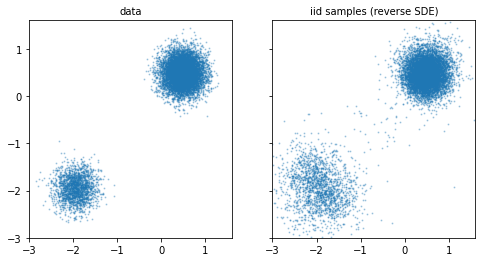

In [5]:
samples = ex.iid_samples(model, n=10_000, steps=500)
fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)
plotting.scatter(ax[0], x[:10_000], title='data'); plotting.scatter(ax[1], samples, title='iid samples (reverse SDE)')
for a in ax: a.set_xlim(-3, 1.6); a.set_ylim(-3, 1.6)
w_data = float((x.sum(1) < 0).double().mean()); w_iid = float((samples.sum(1) < 0).double().mean())
print(f'weight of the small mode (x+y<0): data {w_data:.3f}  | iid {w_iid:.3f}  | exact 0.2')

## 5. Why is small `t` hard?
The DSM regression target is `-ε / s(t)`. Its *variance* grows like `1/s(t)²` as `t → 0`, while the quantity we
want (the true score, which we know exactly for a Gaussian mixture) stays bounded near the modes.
So near `t = 0` the training signal is almost pure noise — the root cause the paper addresses.

Text(0.5, 1.0, 'signal-to-noise of DSM collapses at small t')

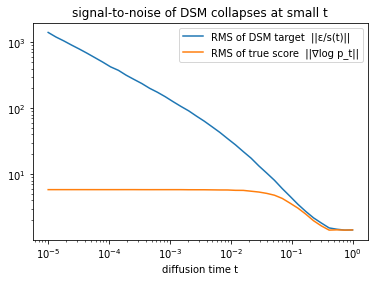

In [6]:
ts = torch.logspace(-5, 0, 40)
x0 = x[:2000]
target_norm, true_norm = [], []
truth = models.AnalyticModel(lambda xx, tt: info['gmm'].log_p_t(xx, tt, info['shift'], info['scale']))
for tv in ts:
    tt = torch.full((len(x0),), float(tv))
    xt, eps, std = sde.perturb(x0, tt)
    target_norm.append(float(((eps / std) ** 2).sum(1).mean().sqrt()))
    true_norm.append(float((truth.score(xt, tt) ** 2).sum(1).mean().sqrt()))
plt.figure(figsize=(6, 4))
plt.loglog(ts, target_norm, label='RMS of DSM target  ||ε/s(t)||')
plt.loglog(ts, true_norm, label='RMS of true score  ||∇log p_t||')
plt.xlabel('diffusion time t'); plt.legend(); plt.title('signal-to-noise of DSM collapses at small t')

## Exercises
1. Stop the reverse SDE at `t_min = 0.05` (`sampling.sample_reverse_sde(model, 10000, 2, t_min=0.05)`). What happens to the modes?
2. Train with fewer steps: `ex.get_model('gmm_diffusion', steps=500)` and compare samples.
3. Replace `EnergyNet` by `ScoreNet` (see `scoremd/models.py`). Does iid sampling change?